<div align="center">
  <img src="https://raw.githubusercontent.com/WSU-AI-in-ME/ai-in-me-1/main/img/wsu_logo_horizontal.png" alt="Wayne State University Logo" width="320">
  <h1>Practice 7: Decision Trees and Ensemble Experiments</h1>
</div>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/WSU-AI-in-ME/ai-in-me-1/blob/main/practice/week07/practice07_decision_trees_and_ensembles_solution.ipynb)

### ME 5995: AI in Mechanical Engineering I: Fundamentals of Manufacturing Data Science

Wayne State University

[Course Repository](https://github.com/WSU-AI-in-ME/ai-in-me-1)

[Practice Index](https://github.com/WSU-AI-in-ME/ai-in-me-1/blob/main/Practice_index.ipynb)

**Version:** One Possible Solution

**Practice:** Optional, ungraded, no submission

Open in Colab and save a personal copy before editing.
Canvas controls assignment dates and submission requirements.

## Student Information

Double-click this Markdown cell to edit.

**Student name:** Instructor Example  
**WSU AccessID:** example00

<a id="practice-guide"></a>
## How to use this Practice

Six activities practice reading a tree, controlling depth, comparing forests,
selecting from validation evidence and interpreting class errors. Finish with
one supplied importance example. Prerequisites: Weeks 5 and 6 classification
metrics, validation and cutter grouping.

Run each completed example, make the stated comparison and check the output.
A brief note is enough; these are optional self-study activities, not submissions.

1. [A1: Follow a tree path](#a1)
2. [B1: Compare depth limits](#b1)
3. [C3: Random feature candidates](#c3)
4. [D1: PHM tree comparison](#d1)
5. [D2: PHM forest comparison](#d2)
6. [D3: Class errors](#d3)
7. [Guided: Importance](#d4): run and read; no written task

[Optional additional practice](#additional-practice) later in this same notebook provides Gini calculations,
regression, extrapolation, pruning, bootstrap, bagging, forest-size experiments,
boosting and correlated-feature interpretation. They are **not needed for HW4**.
[Self-check](practice07_decision_trees_and_ensembles_solution.ipynb): attempt the comparisons before reading.

Run the import and synthetic setup cells before A1/B1/C3. Run the PHM setup
before D1/D2/D3 and the importance example. Restart and Run all for a fresh run.

Software: numpy, pandas, matplotlib, scikit-learn and notebook support.
Colab supplies these packages. Local users install them in their local Python
environment. Internet is needed for the course CSV.

In [1]:
# Run this setup once after restarting the runtime. Imports make library names available.
# numpy handles numerical arrays; pandas handles tables; matplotlib creates figures.
# sklearn supplies the models and metrics. display shows readable notebook tables.

# PROVIDED: run once before any module. No additional installation is needed in Colab.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier, GradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay, mean_squared_error
from sklearn.inspection import permutation_importance
from sklearn.dummy import DummyClassifier

## A/B/C provided setup: invented measurements

All synthetic inputs and responses below are dimensionless invented values,
not PHM measurements or physical safety rules. The classification label is
generated from a noisy relation between two inputs. A fixed seed keeps
comparisons reproducible; the noise makes perfect held-out prediction unlikely.
`X_toy_fit` contains training inputs; `X_toy_valid` contains separate validation
inputs. `y_toy_fit` and `y_toy_valid` contain their binary class labels.

In [2]:
# PROVIDED SETUP: keep this data-generation and plotting infrastructure unchanged.
# Synthetic inputs and responses are dimensionless invented values, not sensor measurements.
# Each row is one observation; the two input columns are features, not class labels.
# Model fitting and scoring appear explicitly in the activities; the helper only draws a fitted model.

# Resetting the generator seed reproduces the same synthetic observations for comparisons.
rng = np.random.default_rng(42)
# Create 240 rows and two uniformly sampled, dimensionless predictor columns.
X_toy = rng.uniform(-1, 1, (240, 2))
toy_noise = rng.normal(0, 0.35, 240)
toy_response = X_toy[:, 0] + 0.7 * X_toy[:, 1] + toy_noise
# Add noise to an invented relation, compare with zero, then encode False/True as classes 0/1.
y_toy = (toy_response > 0).astype(int)
# Split matching input/label rows together; stratification approximately preserves class proportions.
X_toy_fit, X_toy_valid, y_toy_fit, y_toy_valid = train_test_split(X_toy, y_toy, test_size=0.4, stratify=y_toy, random_state=42)

def plot_toy_regions(model):
    """Provided plotting only: no fitting or score calculation."""
    # PROVIDED PLOTTING: build coordinates covering both toy inputs to display fitted class regions.
    grid_x, grid_y = np.meshgrid(np.linspace(-1, 1, 120), np.linspace(-1, 1, 120))
    # ravel flattens grid coordinates; column_stack forms two input columns for prediction.
    grid = np.column_stack([grid_x.ravel(), grid_y.ravel()])
    fig, ax = plt.subplots(figsize=(5, 3.5))
    # predict applies the already fitted model; it does not update its learned rules.
    model_query_prediction = model.predict(grid)
    # Restore predicted classes to the grid shape so contourf can color the learned regions.
    ax.contourf(grid_x, grid_y, model_query_prediction.reshape(grid_x.shape), levels=[-0.5, 0.5, 1.5], cmap='coolwarm', alpha=0.25)
    ax.scatter(X_toy_valid[:, 0], X_toy_valid[:, 1], c=y_toy_valid, cmap='coolwarm', edgecolors='black', s=18)
    ax.set(xlabel='Input 1 (dimensionless)', ylabel='Input 2 (dimensionless)', title='Fitted regions and validation labels')
    plt.tight_layout()
    plt.show()

<a id="a1"></a>

### A1: Follow a path and inspect a leaf

A node tests one feature against a threshold. Left means <=; right means >. A leaf reports training-class proportions. Its probability is not a calibrated risk estimate.

**Completed example:** Run unchanged first.

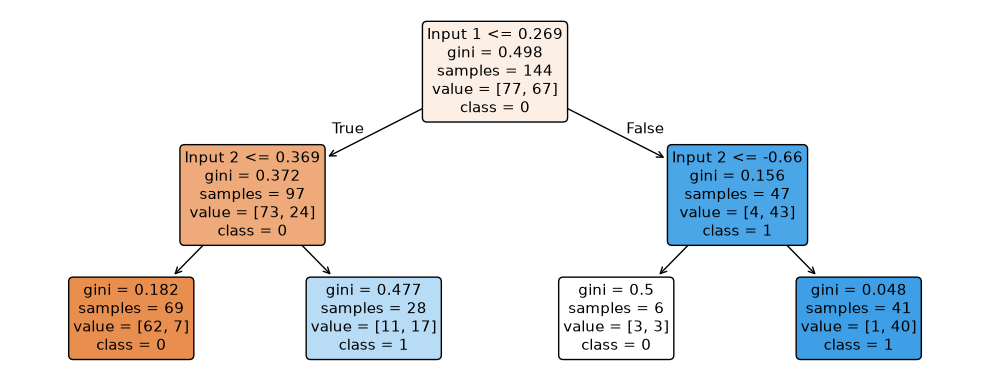

Example class / probabilities: [0] [[0.89855072 0.10144928]]


In [3]:
# Read each <= condition from the root to a leaf: left is True, right is False.
# The probe has shape (1, 2): one observation with two dimensionless input values.
# Probability columns follow model.classes_; they summarize training labels in the reached leaf.

# max_depth limits splits along a path; None removes this explicit depth bound.
small_tree = DecisionTreeClassifier(max_depth=2, random_state=42)
# fit learns model parameters or tree rules from the supplied input rows and matching targets.
small_tree.fit(X_toy_fit, y_toy_fit)
plt.figure(figsize=(10, 4))
plot_tree(small_tree, feature_names=['Input 1', 'Input 2'], class_names=['0', '1'], filled=True, rounded=True)
plt.tight_layout()
plt.show()
probe = np.array([[-0.8, -0.5]])
# predict applies the already fitted model; it does not update its learned rules.
small_tree_query_prediction = small_tree.predict(probe)
print('Example class / probabilities:', small_tree_query_prediction, small_tree.predict_proba(probe))

**Try it yourself:** Use [0.8, 0.5]. Record the split conditions and predicted class. Explain what the leaf probability counts.

Predict, run and compare. One short note is enough.

In [4]:
# Read each <= condition from the root to a leaf: left is True, right is False.
# The probe has shape (1, 2): one observation with two dimensionless input values.
# Probability columns follow model.classes_; they summarize training labels in the reached leaf.

probe_student = np.array([[0.8, 0.5]])
# predict applies the already fitted model; it does not update its learned rules.
small_tree_query_prediction = small_tree.predict(probe_student)
print(small_tree_query_prediction, small_tree.predict_proba(probe_student))

[1] [[0.02439024 0.97560976]]


**Self-check:** Trace the plotted conditions for Input 1 and Input 2 using <= on the left. The positive probe reaches a class-1 leaf; its proportions summarize training labels in that leaf.

<a id="b1"></a>

### B1: Maximum depth

Depth limits the longest path; more depth permits finer regions.

**Completed example:** Run unchanged first.

Actual depth / leaves: 2 4
depth_example
Training F1: 0.838
Validation F1: 0.866


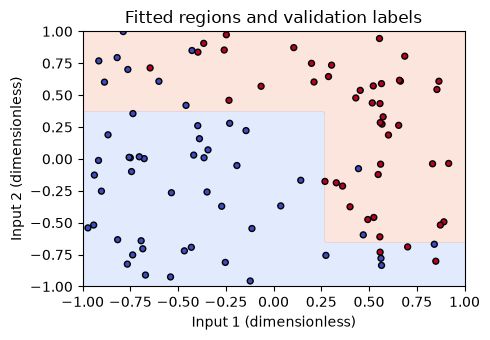

In [5]:
# Change only the permitted depth; keep the data and other controls fixed.
# Compare training and validation scores together with the boundary plot.

# max_depth limits splits along a path; None removes this explicit depth bound.
# min_samples_leaf sets the minimum training sample count in every terminal leaf.
# ccp_alpha=0 disables cost-complexity pruning; positive values penalize extra leaves.
depth_example = DecisionTreeClassifier(max_depth=2, min_samples_leaf=1, ccp_alpha=0.0, random_state=42)
# fit learns model parameters or tree rules from the supplied input rows and matching targets.
depth_example.fit(X_toy_fit, y_toy_fit)
print('Actual depth / leaves:', depth_example.get_depth(), depth_example.get_n_leaves())
# predict applies the already fitted model; it does not update its learned rules.
depth_example_fit_prediction = depth_example.predict(X_toy_fit)
depth_example_valid_prediction = depth_example.predict(X_toy_valid)
# Give true labels first and predictions second. F1 is dimensionless, with larger values better.
depth_example_fit_f1 = f1_score(y_toy_fit, depth_example_fit_prediction)
depth_example_valid_f1 = f1_score(y_toy_valid, depth_example_valid_prediction)
print('depth_example')
print('Training F1:', round(depth_example_fit_f1, 3))
print('Validation F1:', round(depth_example_valid_f1, 3))
plot_toy_regions(depth_example)

**Try it yourself:** Compare depth 2, 5 and None by changing one setting. Cite training and validation scores.

Predict, run and compare. One short note is enough.

Actual depth / leaves: 8 23
depth_student
Training F1: 1.0
Validation F1: 0.872


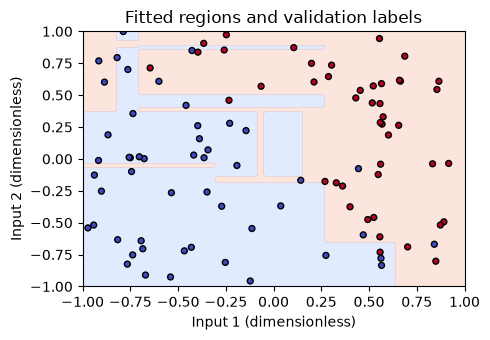

In [6]:
# Change only the permitted depth; keep the data and other controls fixed.
# Compare training and validation scores together with the boundary plot.

# max_depth limits splits along a path; None removes this explicit depth bound.
# min_samples_leaf sets the minimum training sample count in every terminal leaf.
# ccp_alpha=0 disables cost-complexity pruning; positive values penalize extra leaves.
depth_student = DecisionTreeClassifier(max_depth=None, min_samples_leaf=1, ccp_alpha=0.0, random_state=42)
# fit learns model parameters or tree rules from the supplied input rows and matching targets.
depth_student.fit(X_toy_fit, y_toy_fit)
print('Actual depth / leaves:', depth_student.get_depth(), depth_student.get_n_leaves())
# predict applies the already fitted model; it does not update its learned rules.
depth_student_fit_prediction = depth_student.predict(X_toy_fit)
depth_student_valid_prediction = depth_student.predict(X_toy_valid)
# Give true labels first and predictions second. F1 is dimensionless, with larger values better.
depth_student_fit_f1 = f1_score(y_toy_fit, depth_student_fit_prediction)
depth_student_valid_f1 = f1_score(y_toy_valid, depth_student_valid_prediction)
print('depth_student')
print('Training F1:', round(depth_student_fit_f1, 3))
print('Validation F1:', round(depth_student_valid_f1, 3))
plot_toy_regions(depth_student)

In [7]:
# Change only the permitted depth; keep the data and other controls fixed.
# Compare training and validation scores together with the boundary plot.
# PROVIDED SELF-CHECK: explicit blocks compare the requested settings; no loop needs to be reconstructed.

print('max_depth:', 2)
# max_depth limits splits along a path; None removes this explicit depth bound.
# min_samples_leaf sets the minimum training sample count in every terminal leaf.
# ccp_alpha=0 disables cost-complexity pruning; positive values penalize extra leaves.
comparison_tree = DecisionTreeClassifier(max_depth=2, min_samples_leaf=1, ccp_alpha=0.0, random_state=42)
# fit learns model parameters or tree rules from the supplied input rows and matching targets.
comparison_tree.fit(X_toy_fit, y_toy_fit)
print('Actual depth / leaves:', comparison_tree.get_depth(), comparison_tree.get_n_leaves())
# predict applies the already fitted model; it does not update its learned rules.
comparison_tree_fit_prediction = comparison_tree.predict(X_toy_fit)
comparison_tree_valid_prediction = comparison_tree.predict(X_toy_valid)
# Give true labels first and predictions second. F1 is dimensionless, with larger values better.
comparison_tree_fit_f1 = f1_score(y_toy_fit, comparison_tree_fit_prediction)
comparison_tree_valid_f1 = f1_score(y_toy_valid, comparison_tree_valid_prediction)
print('comparison_tree')
print('Training F1:', round(comparison_tree_fit_f1, 3))
print('Validation F1:', round(comparison_tree_valid_f1, 3))
print('max_depth:', 5)
comparison_tree = DecisionTreeClassifier(max_depth=5, min_samples_leaf=1, ccp_alpha=0.0, random_state=42)
comparison_tree.fit(X_toy_fit, y_toy_fit)
print('Actual depth / leaves:', comparison_tree.get_depth(), comparison_tree.get_n_leaves())
comparison_tree_fit_prediction = comparison_tree.predict(X_toy_fit)
comparison_tree_valid_prediction = comparison_tree.predict(X_toy_valid)
comparison_tree_fit_f1 = f1_score(y_toy_fit, comparison_tree_fit_prediction)
comparison_tree_valid_f1 = f1_score(y_toy_valid, comparison_tree_valid_prediction)
print('comparison_tree')
print('Training F1:', round(comparison_tree_fit_f1, 3))
print('Validation F1:', round(comparison_tree_valid_f1, 3))
print('max_depth:', None)
comparison_tree = DecisionTreeClassifier(max_depth=None, min_samples_leaf=1, ccp_alpha=0.0, random_state=42)
comparison_tree.fit(X_toy_fit, y_toy_fit)
print('Actual depth / leaves:', comparison_tree.get_depth(), comparison_tree.get_n_leaves())
comparison_tree_fit_prediction = comparison_tree.predict(X_toy_fit)
comparison_tree_valid_prediction = comparison_tree.predict(X_toy_valid)
comparison_tree_fit_f1 = f1_score(y_toy_fit, comparison_tree_fit_prediction)
comparison_tree_valid_f1 = f1_score(y_toy_valid, comparison_tree_valid_prediction)
print('comparison_tree')
print('Training F1:', round(comparison_tree_fit_f1, 3))
print('Validation F1:', round(comparison_tree_valid_f1, 3))

max_depth: 2
Actual depth / leaves: 2 4
comparison_tree
Training F1: 0.838
Validation F1: 0.866
max_depth: 5
Actual depth / leaves: 5 17
comparison_tree
Training F1: 0.954
Validation F1: 0.884
max_depth: None
Actual depth / leaves: 8 23
comparison_tree
Training F1: 1.0
Validation F1: 0.872


**Self-check:** Training fit improves with capacity; validation need not improve. Use the displayed pair of scores and boundary complexity, not training score alone.

<a id="c3"></a>

### C3: Random features in Random Forest

Random Forest adds random candidate-feature subsets at each split to bootstrap sampling. This can reduce similarity among trees.

**Completed example:** Run unchanged first.

In [8]:
# max_features controls how many candidate input columns are considered at each split.
# With two toy inputs, sqrt considers one feature and 1.0 considers both.
# These are per-node candidate subsets, not a one-time removal of input columns.

# The forest combines bootstrapped trees and random feature candidates at each split.
# n_estimators counts member trees; random_state makes the randomized fit reproducible.
# n_jobs=1 uses one worker for reproducible, modest resource use in this exercise.
ensemble = RandomForestClassifier(n_estimators=80, max_features=1.0, random_state=42, n_jobs=1)
# fit learns model parameters or tree rules from the supplied input rows and matching targets.
ensemble.fit(X_toy_fit, y_toy_fit)
# predict applies the already fitted model; it does not update its learned rules.
ensemble_fit_prediction = ensemble.predict(X_toy_fit)
ensemble_valid_prediction = ensemble.predict(X_toy_valid)
# Give true labels first and predictions second. F1 is dimensionless, with larger values better.
ensemble_fit_f1 = f1_score(y_toy_fit, ensemble_fit_prediction)
ensemble_valid_f1 = f1_score(y_toy_valid, ensemble_valid_prediction)
print('Ensemble')
print('Training F1:', round(ensemble_fit_f1, 3))
print('Validation F1:', round(ensemble_valid_f1, 3))

Ensemble
Training F1: 1.0
Validation F1: 0.896


**Try it yourself:** Compare max_features=1.0 and 'sqrt'. With two inputs, sqrt considers one candidate per node. Does changing it guarantee better validation F1?

Predict, run and compare. One short note is enough.

In [9]:
# max_features controls how many candidate input columns are considered at each split.
# With two toy inputs, sqrt considers one feature and 1.0 considers both.
# These are per-node candidate subsets, not a one-time removal of input columns.

# The forest combines bootstrapped trees and random feature candidates at each split.
# n_estimators counts member trees; random_state makes the randomized fit reproducible.
# n_jobs=1 uses one worker for reproducible, modest resource use in this exercise.
ensemble = RandomForestClassifier(n_estimators=80, max_features='sqrt', random_state=42, n_jobs=1)
# fit learns model parameters or tree rules from the supplied input rows and matching targets.
ensemble.fit(X_toy_fit, y_toy_fit)
# predict applies the already fitted model; it does not update its learned rules.
ensemble_fit_prediction = ensemble.predict(X_toy_fit)
ensemble_valid_prediction = ensemble.predict(X_toy_valid)
# Give true labels first and predictions second. F1 is dimensionless, with larger values better.
ensemble_fit_f1 = f1_score(y_toy_fit, ensemble_fit_prediction)
ensemble_valid_f1 = f1_score(y_toy_valid, ensemble_valid_prediction)
print('Ensemble')
print('Training F1:', round(ensemble_fit_f1, 3))
print('Validation F1:', round(ensemble_valid_f1, 3))

Ensemble
Training F1: 1.0
Validation F1: 0.938


**Self-check:** The setting changes split diversity and individual-tree strength. Their trade-off is data-dependent.

## Dataset and engineering context

One PHM row represents one machining cut. The course feature table contains
315 cuts per cutter c1, c4 and c6 (945 rows). Original recordings contain three
force channels (N), three vibration channels (g), and one AE-RMS channel (V),
documented at 50 kHz. These notebooks use supplied full-record summaries,
not raw waveforms. Mean and SD retain their channel units.

Target `wear_level` is a **course-defined** current-cut category from mean
flute wear: 0 Slight-wear (<=75 micrometers), 1 Intermediate-wear
(>75 and <150 micrometers), 2 Severe-wear (>=150 micrometers).
These are not official challenge classes or industrial replacement limits.
This is current-cut classification, not forecasting.

Eleven documented sensor inputs are fixed. Wear measurements, target labels,
cutter IDs and cut numbers are excluded from predictors. IDs define groups.
Axis-aligned trees use threshold splits; scaling is not required here.
This differs from distance-based methods and regularized linear models.

Source and curation/redistribution documentation:
[PHM official challenge](https://phmsociety.org/phm_competition/2010-phm-society-conference-data-challenge/),
[course provenance](https://github.com/WSU-AI-in-ME/ai-in-me-1/blob/main/data/phm2010/README.md),
[feature definitions](https://github.com/WSU-AI-in-ME/ai-in-me-1/blob/main/data/phm2010/features/DATA_DICTIONARY.md).
Use the existing course distribution; this draft creates no new data subset.
Cite the original challenge and course feature documentation in reused work.

## D: PHM model comparison and interpretation

c1 is fitting data and c4 is validation for an absent cutter. This direction
gives one transfer comparison, not broad machine/material generalization.
Do not use c6 in Practice 7. HW4 reserves it for evaluation after model selection
within that exercise; it has already been used in this course.
Macro-F1 averages the F1 of all three classes equally. Counts matter when
interpreting a score. All classes are included, with undefined divisions set to zero.

In [10]:
# PROVIDED SETUP: one CSV row is one machining cut, not one raw signal sample.
# Force features are in N, vibration features in g, and AE-RMS features in V.
# Mean and standard deviation retain the original channel units.
# c1 supplies training rows; c4 supplies validation rows for a cutter absent from fitting.
# Keep cutter IDs and wear measurements out of the predictor columns.

# Load the documented course CSV from its public URL; the table includes inputs and metadata.
data = pd.read_csv('https://raw.githubusercontent.com/WSU-AI-in-ME/ai-in-me-1/main/data/phm2010/features/phm2010_features.csv')
# Only these named sensor summaries enter the models. Column order stays identical across datasets.
features = ['force_x_mean', 'force_x_sd', 'force_y_mean', 'force_y_sd', 'force_z_mean', 'force_z_sd', 'vibration_x_sd', 'vibration_y_sd', 'vibration_z_sd', 'ae_rms_mean', 'ae_rms_sd']
# This Boolean mask is True for c1 rows and False for all other cutter rows.
fit_rows = data['cutter_id'] == 'c1'
# This separate mask selects c4; it must not be used to train the candidate models.
valid_rows = data['cutter_id'] == 'c4'
# X contains predictor columns: c1 rows by 11 sensor features.
X_fit = data.loc[fit_rows, features]
# y contains one course-defined wear class (0, 1 or 2) per c1 row.
y_fit = data.loc[fit_rows, 'wear_level']
# Use exactly the same feature columns and order for the held-out c4 inputs.
X_valid = data.loc[valid_rows, features]
# c4 labels are used for validation scoring and selection, not fitting.
y_valid = data.loc[valid_rows, 'wear_level']
display(pd.crosstab(data.loc[fit_rows | valid_rows, 'cutter_id'], data.loc[fit_rows | valid_rows, 'wear_level']))
majority_baseline = DummyClassifier(strategy='most_frequent')
# fit learns model parameters or tree rules from the supplied input rows and matching targets.
majority_baseline.fit(X_fit, y_fit)
# predict applies the already fitted model; it does not update its learned rules.
majority_baseline_fit_prediction = majority_baseline.predict(X_fit)
majority_baseline_valid_prediction = majority_baseline.predict(X_valid)
# Give true labels first and predictions second. F1 is dimensionless, with larger values better.
# macro averages class-wise F1 equally; labels fixes class order and zero_division handles undefined ratios.
majority_baseline_fit_f1 = f1_score(y_fit, majority_baseline_fit_prediction, labels=[0, 1, 2], average='macro', zero_division=0)
majority_baseline_valid_f1 = f1_score(y_valid, majority_baseline_valid_prediction, labels=[0, 1, 2], average='macro', zero_division=0)
print('Training-majority baseline')
print('Training macro-F1:', round(majority_baseline_fit_f1, 3))
print('Validation macro-F1:', round(majority_baseline_valid_f1, 3))

wear_level,0,1,2
cutter_id,,,
c1,27,259,29
c4,75,194,46


Training-majority baseline
Training macro-F1: 0.301
Validation macro-F1: 0.254


<a id="d1"></a>

### D1: PHM depth comparison

Keep rows, features and seed identical while changing tree depth. max_depth is an upper limit, not a requirement to keep splitting. Inspect actual depth and leaves when scores match.

**Completed example:** Run unchanged first.

In [11]:
# All PHM tree comparisons fit c1 and predict c4 with the same 11 inputs.
# A depth limit is an upper bound. The fitted tree may stop splitting sooner.

# max_depth limits splits along a path; None removes this explicit depth bound.
# min_samples_leaf sets the minimum training sample count in every terminal leaf.
phm_tree = DecisionTreeClassifier(max_depth=2, min_samples_leaf=5, random_state=42)
# fit learns model parameters or tree rules from the supplied input rows and matching targets.
phm_tree.fit(X_fit, y_fit)
# predict applies the already fitted model; it does not update its learned rules.
phm_tree_fit_prediction = phm_tree.predict(X_fit)
phm_tree_valid_prediction = phm_tree.predict(X_valid)
# Give true labels first and predictions second. F1 is dimensionless, with larger values better.
# macro averages class-wise F1 equally; labels fixes class order and zero_division handles undefined ratios.
phm_tree_fit_f1 = f1_score(y_fit, phm_tree_fit_prediction, labels=[0, 1, 2], average='macro', zero_division=0)
phm_tree_valid_f1 = f1_score(y_valid, phm_tree_valid_prediction, labels=[0, 1, 2], average='macro', zero_division=0)
print('Depth 2')
print('Training macro-F1:', round(phm_tree_fit_f1, 3))
print('Validation macro-F1:', round(phm_tree_valid_f1, 3))

Depth 2
Training macro-F1: 0.993
Validation macro-F1: 0.63


**Try it yourself:** Run depths 2, 4 and 8; record the score pairs and actual depth. Explain identical results if they occur, then try depth 1. Choose from validation evidence.

Predict, run and compare. One short note is enough.

In [12]:
# All PHM tree comparisons fit c1 and predict c4 with the same 11 inputs.
# A depth limit is an upper bound. The fitted tree may stop splitting sooner.

# max_depth limits splits along a path; None removes this explicit depth bound.
# min_samples_leaf sets the minimum training sample count in every terminal leaf.
phm_student = DecisionTreeClassifier(max_depth=8, min_samples_leaf=5, random_state=42)
# fit learns model parameters or tree rules from the supplied input rows and matching targets.
phm_student.fit(X_fit, y_fit)
# predict applies the already fitted model; it does not update its learned rules.
phm_student_fit_prediction = phm_student.predict(X_fit)
phm_student_valid_prediction = phm_student.predict(X_valid)
# Give true labels first and predictions second. F1 is dimensionless, with larger values better.
# macro averages class-wise F1 equally; labels fixes class order and zero_division handles undefined ratios.
phm_student_fit_f1 = f1_score(y_fit, phm_student_fit_prediction, labels=[0, 1, 2], average='macro', zero_division=0)
phm_student_valid_f1 = f1_score(y_valid, phm_student_valid_prediction, labels=[0, 1, 2], average='macro', zero_division=0)
print('Depth 8')
print('Training macro-F1:', round(phm_student_fit_f1, 3))
print('Validation macro-F1:', round(phm_student_valid_f1, 3))

Depth 8
Training macro-F1: 0.993
Validation macro-F1: 0.63


In [13]:
# All PHM tree comparisons fit c1 and predict c4 with the same 11 inputs.
# A depth limit is an upper bound. The fitted tree may stop splitting sooner.
# PROVIDED SELF-CHECK: explicit blocks compare the requested settings; no loop needs to be reconstructed.

rows = []
# max_depth limits splits along a path; None removes this explicit depth bound.
# min_samples_leaf sets the minimum training sample count in every terminal leaf.
model = DecisionTreeClassifier(max_depth=1, min_samples_leaf=5, random_state=42)
# fit learns model parameters or tree rules from the supplied input rows and matching targets.
model.fit(X_fit, y_fit)
# predict applies the already fitted model; it does not update its learned rules.
model_fit_prediction = model.predict(X_fit)
model_valid_prediction = model.predict(X_valid)
# Give true labels first and predictions second. F1 is dimensionless, with larger values better.
# macro averages class-wise F1 equally; labels fixes class order and zero_division handles undefined ratios.
model_fit_f1 = f1_score(y_fit, model_fit_prediction, labels=[0, 1, 2], average='macro', zero_division=0)
model_valid_f1 = f1_score(y_valid, model_valid_prediction, labels=[0, 1, 2], average='macro', zero_division=0)
comparison_score_row = ['Depth ' + str(1), model_fit_f1, model_valid_f1]
rows.append(comparison_score_row)
print('Depth limit / actual depth / leaves:', 1, model.get_depth(), model.get_n_leaves())
model = DecisionTreeClassifier(max_depth=2, min_samples_leaf=5, random_state=42)
model.fit(X_fit, y_fit)
model_fit_prediction = model.predict(X_fit)
model_valid_prediction = model.predict(X_valid)
model_fit_f1 = f1_score(y_fit, model_fit_prediction, labels=[0, 1, 2], average='macro', zero_division=0)
model_valid_f1 = f1_score(y_valid, model_valid_prediction, labels=[0, 1, 2], average='macro', zero_division=0)
comparison_score_row = ['Depth ' + str(2), model_fit_f1, model_valid_f1]
rows.append(comparison_score_row)
print('Depth limit / actual depth / leaves:', 2, model.get_depth(), model.get_n_leaves())
model = DecisionTreeClassifier(max_depth=4, min_samples_leaf=5, random_state=42)
model.fit(X_fit, y_fit)
model_fit_prediction = model.predict(X_fit)
model_valid_prediction = model.predict(X_valid)
model_fit_f1 = f1_score(y_fit, model_fit_prediction, labels=[0, 1, 2], average='macro', zero_division=0)
model_valid_f1 = f1_score(y_valid, model_valid_prediction, labels=[0, 1, 2], average='macro', zero_division=0)
comparison_score_row = ['Depth ' + str(4), model_fit_f1, model_valid_f1]
rows.append(comparison_score_row)
print('Depth limit / actual depth / leaves:', 4, model.get_depth(), model.get_n_leaves())
model = DecisionTreeClassifier(max_depth=8, min_samples_leaf=5, random_state=42)
model.fit(X_fit, y_fit)
model_fit_prediction = model.predict(X_fit)
model_valid_prediction = model.predict(X_valid)
model_fit_f1 = f1_score(y_fit, model_fit_prediction, labels=[0, 1, 2], average='macro', zero_division=0)
model_valid_f1 = f1_score(y_valid, model_valid_prediction, labels=[0, 1, 2], average='macro', zero_division=0)
comparison_score_row = ['Depth ' + str(8), model_fit_f1, model_valid_f1]
rows.append(comparison_score_row)
print('Depth limit / actual depth / leaves:', 8, model.get_depth(), model.get_n_leaves())
comparison_table = pd.DataFrame(rows, columns=['Model', 'Training macro-F1', 'Validation macro-F1'])
# Round only the display; retain full-precision values when comparing candidates or checking ties.
display(comparison_table.round(3))

Depth limit / actual depth / leaves: 1 1 2
Depth limit / actual depth / leaves: 2 2 4
Depth limit / actual depth / leaves: 4 2 4
Depth limit / actual depth / leaves: 8 2 4


,Model,Training macro-F1,Validation macro-F1
0,Depth 1,0.617,0.467
1,Depth 2,0.993,0.630
2,Depth 4,0.993,0.630
3,Depth 8,0.993,0.630


**Self-check:** In the checked example, limits 2/4/8 all produce actual depth 2 and identical scores. Raising a bound does not force extra splits. Depth 1 restricts this tree. Prefer the largest validation macro-F1 in the declared set and the smaller limit for a tie.

<a id="d2"></a>

### D2: Select among fixed forest candidates

This small candidate comparison is allowed on validation. Once selected, evaluate on separate data without further tuning.

**Completed example:** Run unchanged first.

In [14]:
# The forest comparisons keep tree count, depth, leaf size and data fixed.
# With 11 inputs, sqrt, 0.5 and 1.0 allow 3, 5 and 11 candidate features per split.
# c4 scores may guide this comparison; they then become model-selection evidence.

# min_samples_leaf sets the minimum training sample count in every terminal leaf.
# The forest combines bootstrapped trees and random feature candidates at each split.
# n_estimators counts member trees; random_state makes the randomized fit reproducible.
# n_jobs=1 uses one worker for reproducible, modest resource use in this exercise.
forest_reference = RandomForestClassifier(n_estimators=100, max_depth=8, min_samples_leaf=5, max_features='sqrt', random_state=42, n_jobs=1)
# fit learns model parameters or tree rules from the supplied input rows and matching targets.
forest_reference.fit(X_fit, y_fit)
# predict applies the already fitted model; it does not update its learned rules.
forest_reference_fit_prediction = forest_reference.predict(X_fit)
forest_reference_valid_prediction = forest_reference.predict(X_valid)
# Give true labels first and predictions second. F1 is dimensionless, with larger values better.
# macro averages class-wise F1 equally; labels fixes class order and zero_division handles undefined ratios.
forest_reference_fit_f1 = f1_score(y_fit, forest_reference_fit_prediction, labels=[0, 1, 2], average='macro', zero_division=0)
forest_reference_valid_f1 = f1_score(y_valid, forest_reference_valid_prediction, labels=[0, 1, 2], average='macro', zero_division=0)
print('sqrt')
print('Training macro-F1:', round(forest_reference_fit_f1, 3))
print('Validation macro-F1:', round(forest_reference_valid_f1, 3))

sqrt
Training macro-F1: 1.0
Validation macro-F1: 0.654


**Try it yourself:** Record sqrt, 0.5 and 1.0. Explain what data enter fitting and selection. Is c4 now an independent final test?

Predict, run and compare. One short note is enough.

In [15]:
# The forest comparisons keep tree count, depth, leaf size and data fixed.
# With 11 inputs, sqrt, 0.5 and 1.0 allow 3, 5 and 11 candidate features per split.
# c4 scores may guide this comparison; they then become model-selection evidence.

# min_samples_leaf sets the minimum training sample count in every terminal leaf.
# The forest combines bootstrapped trees and random feature candidates at each split.
# n_estimators counts member trees; random_state makes the randomized fit reproducible.
# n_jobs=1 uses one worker for reproducible, modest resource use in this exercise.
forest_student = RandomForestClassifier(n_estimators=100, max_depth=8, min_samples_leaf=5, max_features=0.5, random_state=42, n_jobs=1)
# fit learns model parameters or tree rules from the supplied input rows and matching targets.
forest_student.fit(X_fit, y_fit)
# predict applies the already fitted model; it does not update its learned rules.
forest_student_fit_prediction = forest_student.predict(X_fit)
forest_student_valid_prediction = forest_student.predict(X_valid)
# Give true labels first and predictions second. F1 is dimensionless, with larger values better.
# macro averages class-wise F1 equally; labels fixes class order and zero_division handles undefined ratios.
forest_student_fit_f1 = f1_score(y_fit, forest_student_fit_prediction, labels=[0, 1, 2], average='macro', zero_division=0)
forest_student_valid_f1 = f1_score(y_valid, forest_student_valid_prediction, labels=[0, 1, 2], average='macro', zero_division=0)
print('0.5')
print('Training macro-F1:', round(forest_student_fit_f1, 3))
print('Validation macro-F1:', round(forest_student_valid_f1, 3))

0.5
Training macro-F1: 1.0
Validation macro-F1: 0.673


In [16]:
# The forest comparisons keep tree count, depth, leaf size and data fixed.
# With 11 inputs, sqrt, 0.5 and 1.0 allow 3, 5 and 11 candidate features per split.
# c4 scores may guide this comparison; they then become model-selection evidence.
# PROVIDED SELF-CHECK: explicit blocks compare the requested settings; no loop needs to be reconstructed.

rows = []
# min_samples_leaf sets the minimum training sample count in every terminal leaf.
# The forest combines bootstrapped trees and random feature candidates at each split.
# n_estimators counts member trees; random_state makes the randomized fit reproducible.
# n_jobs=1 uses one worker for reproducible, modest resource use in this exercise.
model = RandomForestClassifier(n_estimators=100, max_depth=8, min_samples_leaf=5, max_features='sqrt', random_state=42, n_jobs=1)
# fit learns model parameters or tree rules from the supplied input rows and matching targets.
model.fit(X_fit, y_fit)
# predict applies the already fitted model; it does not update its learned rules.
model_fit_prediction = model.predict(X_fit)
model_valid_prediction = model.predict(X_valid)
# Give true labels first and predictions second. F1 is dimensionless, with larger values better.
# macro averages class-wise F1 equally; labels fixes class order and zero_division handles undefined ratios.
model_fit_f1 = f1_score(y_fit, model_fit_prediction, labels=[0, 1, 2], average='macro', zero_division=0)
model_valid_f1 = f1_score(y_valid, model_valid_prediction, labels=[0, 1, 2], average='macro', zero_division=0)
comparison_score_row = ['max_features ' + str('sqrt'), model_fit_f1, model_valid_f1]
rows.append(comparison_score_row)
model = RandomForestClassifier(n_estimators=100, max_depth=8, min_samples_leaf=5, max_features=0.5, random_state=42, n_jobs=1)
model.fit(X_fit, y_fit)
model_fit_prediction = model.predict(X_fit)
model_valid_prediction = model.predict(X_valid)
model_fit_f1 = f1_score(y_fit, model_fit_prediction, labels=[0, 1, 2], average='macro', zero_division=0)
model_valid_f1 = f1_score(y_valid, model_valid_prediction, labels=[0, 1, 2], average='macro', zero_division=0)
comparison_score_row = ['max_features ' + str(0.5), model_fit_f1, model_valid_f1]
rows.append(comparison_score_row)
model = RandomForestClassifier(n_estimators=100, max_depth=8, min_samples_leaf=5, max_features=1.0, random_state=42, n_jobs=1)
model.fit(X_fit, y_fit)
model_fit_prediction = model.predict(X_fit)
model_valid_prediction = model.predict(X_valid)
model_fit_f1 = f1_score(y_fit, model_fit_prediction, labels=[0, 1, 2], average='macro', zero_division=0)
model_valid_f1 = f1_score(y_valid, model_valid_prediction, labels=[0, 1, 2], average='macro', zero_division=0)
comparison_score_row = ['max_features ' + str(1.0), model_fit_f1, model_valid_f1]
rows.append(comparison_score_row)
comparison_table = pd.DataFrame(rows, columns=['Model', 'Training macro-F1', 'Validation macro-F1'])
# Round only the display; retain full-precision values when comparing candidates or checking ties.
display(comparison_table.round(3))

,Model,Training macro-F1,Validation macro-F1
0,max_features sqrt,1.0,0.654
1,max_features 0.5,1.0,0.673
2,max_features 1.0,1.0,0.679


**Self-check:** c1 enters fitting; c4 enters selection. Reusing c4 to choose settings means its score is development evidence, not an independent final estimate.

<a id="d3"></a>

### D3: Read class errors

Rows are true classes, columns are predictions. A macro-average hides which classes are confused.

**Completed example:** Run unchanged first.

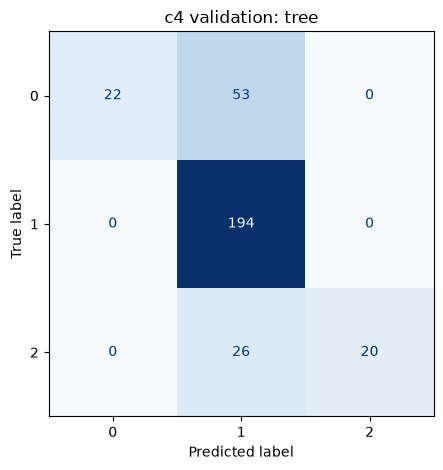

In [17]:
# Use the same class order [0, 1, 2] when comparing both confusion matrices.
# An off-diagonal entry counts one specific actual-class/predicted-class error.
# True class 2 predicted as 0 or 1 is missed Severe; true 0 or 1 predicted as 2 is false Severe.

# max_depth limits splits along a path; None removes this explicit depth bound.
# min_samples_leaf sets the minimum training sample count in every terminal leaf.
error_tree = DecisionTreeClassifier(max_depth=4, min_samples_leaf=5, random_state=42)
# fit learns model parameters or tree rules from the supplied input rows and matching targets.
error_tree.fit(X_fit, y_fit)
# predict applies the already fitted model; it does not update its learned rules.
error_tree_valid_prediction = error_tree.predict(X_valid)
ConfusionMatrixDisplay.from_predictions(y_valid, error_tree_valid_prediction, labels=[0, 1, 2], cmap='Blues', colorbar=False)
plt.title('c4 validation: tree')
plt.tight_layout()
plt.show()

**Try it yourself:** Compare the two matrices. Name the largest off-diagonal cell using actual and predicted class names; distinguish missed Severe from false Severe.

Predict, run and compare. One short note is enough.

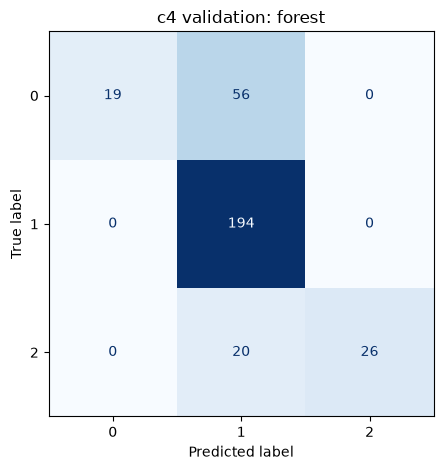

In [18]:
# Use the same class order [0, 1, 2] when comparing both confusion matrices.
# An off-diagonal entry counts one specific actual-class/predicted-class error.
# True class 2 predicted as 0 or 1 is missed Severe; true 0 or 1 predicted as 2 is false Severe.

# min_samples_leaf sets the minimum training sample count in every terminal leaf.
# The forest combines bootstrapped trees and random feature candidates at each split.
# n_estimators counts member trees; random_state makes the randomized fit reproducible.
# n_jobs=1 uses one worker for reproducible, modest resource use in this exercise.
error_forest = RandomForestClassifier(n_estimators=100, max_depth=8, min_samples_leaf=5, max_features='sqrt', random_state=42, n_jobs=1)
# fit learns model parameters or tree rules from the supplied input rows and matching targets.
error_forest.fit(X_fit, y_fit)
# predict applies the already fitted model; it does not update its learned rules.
error_forest_valid_prediction = error_forest.predict(X_valid)
ConfusionMatrixDisplay.from_predictions(y_valid, error_forest_valid_prediction, labels=[0, 1, 2], cmap='Blues', colorbar=False)
plt.title('c4 validation: forest')
plt.tight_layout()
plt.show()

**Self-check:** Use the maximum off-diagonal count, not the darkest diagonal. True Severe predicted 0/1 is missed Severe; true 0/1 predicted Severe is false Severe.

<a id="d4"></a>
## Guided example: Two importance definitions

Run both cells unchanged. Compare training impurity importance with the c4
macro-F1 drop after shuffling a feature. Correlated inputs can substitute for
one another, so a small drop does not prove a sensor is physically irrelevant.
Neither measure establishes causality. Repeat SD describes shuffle variation,
not uncertainty across cutters. No written response or setting change is needed.

In [19]:
# Compare two definitions of importance for one fitted forest, without refitting it.
# Permutation values are changes in validation macro-F1, not physical sensor units.
# Correlated columns may substitute for one another; neither ranking establishes causality.

# min_samples_leaf sets the minimum training sample count in every terminal leaf.
# The forest combines bootstrapped trees and random feature candidates at each split.
# n_estimators counts member trees; random_state makes the randomized fit reproducible.
# n_jobs=1 uses one worker for reproducible, modest resource use in this exercise.
importance_forest = RandomForestClassifier(n_estimators=100, max_depth=8, min_samples_leaf=5, random_state=42, n_jobs=1)
# fit learns model parameters or tree rules from the supplied input rows and matching targets.
importance_forest.fit(X_fit, y_fit)
feature_importance = pd.Series(importance_forest.feature_importances_, index=features)
sorted_importance = feature_importance.sort_values(ascending=False)
# Round only the display; retain full-precision values when comparing candidates or checking ties.
rounded_importance = sorted_importance.round(3)
print(rounded_importance)

vibration_y_sd    0.176
force_x_sd        0.138
force_z_sd        0.127
force_y_mean      0.126
ae_rms_mean       0.118
vibration_x_sd    0.108
vibration_z_sd    0.099
force_y_sd        0.067
force_z_mean      0.033
ae_rms_sd         0.007
force_x_mean      0.001
dtype: float64


,Feature,Impurity importance,Permutation mean drop,Repeat SD
7,vibration_y_sd,0.176,0.068,0.012
6,vibration_x_sd,0.108,0.023,0.013
5,force_z_sd,0.127,0.023,0.005
9,ae_rms_mean,0.118,0.017,0.003
1,force_x_sd,0.138,0.014,0.009
8,vibration_z_sd,0.099,0.003,0.003
2,force_y_mean,0.126,0.003,0.003
0,force_x_mean,0.001,0.000,0.000
4,force_z_mean,0.033,0.000,0.000
3,force_y_sd,0.067,0.000,0.000


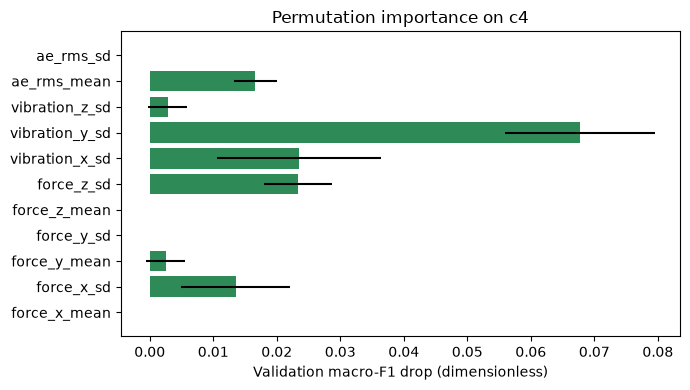

In [20]:
# Compare two definitions of importance for one fitted forest, without refitting it.
# Permutation values are changes in validation macro-F1, not physical sensor units.
# Correlated columns may substitute for one another; neither ranking establishes causality.

# PROVIDED: score drop after shuffling one validation feature; no refitting.
# Refitting is not performed: repeatedly shuffle one validation column and measure the score drop.
permutation = permutation_importance(importance_forest, X_valid, y_valid,
    # Five shuffles give a mean and repeat SD for each column; the score is macro-F1 here.
    scoring='f1_macro', n_repeats=5, random_state=42, n_jobs=1)
# Place both importance definitions side by side; their numerical scales and meanings differ.
importance_table = pd.DataFrame()
importance_table['Feature'] = features
importance_table['Impurity importance'] = importance_forest.feature_importances_
importance_table['Permutation mean drop'] = permutation.importances_mean
importance_table['Repeat SD'] = permutation.importances_std
sorted_importance = importance_table.sort_values('Permutation mean drop', ascending=False)
# Round only the display; retain full-precision values when comparing candidates or checking ties.
rounded_importance = sorted_importance.round(3)
display(rounded_importance)
plt.figure(figsize=(7, 4))
# Horizontal bars show mean score drops; xerr adds shuffle SD, not confidence intervals across cutters.
plt.barh(features, permutation.importances_mean, xerr=permutation.importances_std, color='seagreen')
plt.xlabel('Validation macro-F1 drop (dimensionless)')
plt.title('Permutation importance on c4')
plt.tight_layout()
plt.show()

## Self-study checklist

Rendered notebook checkboxes are not clickable. To record completion, edit
this Markdown cell and change `[ ]` to `[x]`.

- [ ] I compared the settings in the six activities.
- [ ] I distinguished c1 fitting from c4 validation and selection.
- [ ] I read the matrices and the supplied importance example.

No submission is required. The additional examples are optional enrichment.

## Basic route complete: you may stop here

You have finished the six activities and guided importance example that
prepare you for HW4. You do not need to complete the remaining examples.
If you would like more practice, choose a topic below and continue at your
own pace. No additional submission or formal written responses are required.

<a id="additional-practice"></a>
## Optional additional practice

These examples are for students who want to explore further. Choose any topic;
you do not need to work through all 11. The existing setup cells are reused.
A4 also needs the completed regression setup in A3. E1/E2 use the PHM setup.

**Topics:** [A2](#a2), [A3](#a3), [A4](#a4), [B2](#b2), [B3](#b3), [B4](#b4), [C1](#c1), [C2](#c2), [C4](#c4), [E1](#e1), [E2](#e2)

[Return to the basic route guide](#practice-guide)

<a id="a2"></a>

### A2: Compute weighted Gini reduction

Gini = 1 - sum of squared class proportions. Evaluate a split using child sample counts, not an unweighted mean of child impurities.

**Completed example:** Run unchanged first.

In [21]:
# The class counts are invented. Counts divided by the node total give class proportions.
# Gini is dimensionless. Weight each child impurity by its share of the parent observations.
# A larger parent-minus-weighted-child value means a larger local impurity reduction.

# Parent has four samples from each class.
parent_gini = 1 - (4/8)**2 - (4/8)**2
left_gini = 1 - (3/4)**2 - (1/4)**2
right_gini = 1 - (1/4)**2 - (3/4)**2
weighted_gini = (4/8)*left_gini + (4/8)*right_gini
print('Example reduction:', parent_gini - weighted_gini)

Example reduction: 0.125


**Try it yourself:** Complete the three expressions for split B. Which split has the larger reduction? Does greedy split selection guarantee the globally best tree?

Predict, run and compare. No formal written answer is needed.

In [22]:
# The class counts are invented. Counts divided by the node total give class proportions.
# Gini is dimensionless. Weight each child impurity by its share of the parent observations.
# A larger parent-minus-weighted-child value means a larger local impurity reduction.

left_b = 1 - (4/5)**2 - (1/5)**2
right_b = 1 - (0/3)**2 - (3/3)**2
weighted_b = (5/8)*left_b + (3/8)*right_b
print('Split B reduction:', parent_gini - weighted_b)

Split B reduction: 0.3000000000000001


**Self-check:** A reduces Gini by 0.125; B by 0.300, so B is preferred at this node. A local improvement does not guarantee a globally optimal tree.

<a id="a3"></a>

### A3: Regression tree versus class prediction

Regression leaves predict a number, not a category. A squared-error tree makes piecewise constant predictions.

**Completed example:** Run unchanged first.

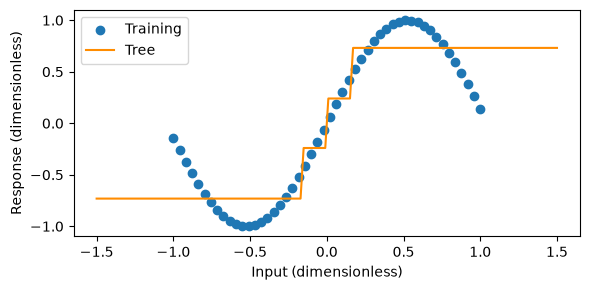

In [23]:
# This example predicts a continuous, dimensionless response rather than a class label.
# For squared-error regression, each leaf predicts the mean training response in that leaf.
# The plotted grid includes inputs outside the observed training range [-1, 1].

# Invented continuous response; squared-error leaves predict a training mean.
# reshape(-1, 1) makes a two-dimensional input table with one feature column.
reg_x = np.linspace(-1, 1, 50).reshape(-1, 1)
# Index column 0 to form the invented continuous response for each training row.
reg_y = np.sin(3 * reg_x[:, 0])
# max_depth limits splits along a path; None removes this explicit depth bound.
reg_tree = DecisionTreeRegressor(max_depth=2, random_state=42)
# fit learns model parameters or tree rules from the supplied input rows and matching targets.
reg_tree.fit(reg_x, reg_y)
# A dense input grid makes the stepwise prediction visible; it supplies no new observed labels.
reg_grid = np.linspace(-1.5, 1.5, 150).reshape(-1, 1)
plt.figure(figsize=(6, 3))
plt.scatter(reg_x[:, 0], reg_y, label='Training')
# predict applies the already fitted model; it does not update its learned rules.
reg_tree_query_prediction = reg_tree.predict(reg_grid)
plt.plot(reg_grid[:, 0], reg_tree_query_prediction, color='darkorange', label='Tree')
plt.xlabel('Input (dimensionless)')
plt.ylabel('Response (dimensionless)')
plt.legend()
plt.tight_layout()
plt.show()

**Try it yourself:** Compare depth 2 with 5. Is lower training MSE sufficient evidence of generalization?

Predict, run and compare. No formal written answer is needed.

Training MSE: 0.0024242874219826743


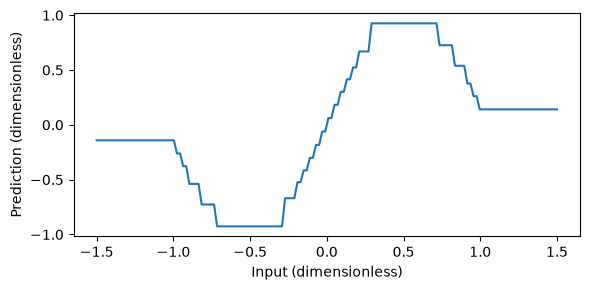

In [24]:
# This example predicts a continuous, dimensionless response rather than a class label.
# For squared-error regression, each leaf predicts the mean training response in that leaf.
# The plotted grid includes inputs outside the observed training range [-1, 1].

# max_depth limits splits along a path; None removes this explicit depth bound.
reg_student = DecisionTreeRegressor(max_depth=5, random_state=42)
# fit learns model parameters or tree rules from the supplied input rows and matching targets.
reg_student.fit(reg_x, reg_y)
# predict applies the already fitted model; it does not update its learned rules.
reg_student_fit_prediction = reg_student.predict(reg_x)
reg_training_mse = mean_squared_error(reg_y, reg_student_fit_prediction)
print('Training MSE:', reg_training_mse)
plt.figure(figsize=(6, 3))
reg_student_query_prediction = reg_student.predict(reg_grid)
plt.plot(reg_grid[:, 0], reg_student_query_prediction)
plt.xlabel('Input (dimensionless)')
plt.ylabel('Prediction (dimensionless)')
plt.tight_layout()
plt.show()

**Self-check:** More leaves lower training MSE and add steps. No held-out responses are evaluated, so this output alone cannot establish generalization.

<a id="a4"></a>

### A4: Extrapolation beyond training inputs

A tree routes any input to an existing leaf. It cannot extend a fitted slope beyond the training range.

**Completed example:** Run unchanged first.

In [25]:
# Both queried inputs lie beyond the largest training input, x=1.
# The tree still routes them to existing leaves; it does not extend a fitted slope.

# max_depth limits splits along a path; None removes this explicit depth bound.
outside_tree = DecisionTreeRegressor(max_depth=3, random_state=42)
# fit learns model parameters or tree rules from the supplied input rows and matching targets.
outside_tree.fit(reg_x, reg_y)
# predict applies the already fitted model; it does not update its learned rules.
outside_tree_query_prediction = outside_tree.predict([[1.2]])
print('Example at x=1.2:', outside_tree_query_prediction)

Example at x=1.2: [0.37131243]


**Try it yourself:** Change the second input to 3.0. Explain why equal predictions do not mean equal physical behavior.

Predict, run and compare. No formal written answer is needed.

In [26]:
# Both queried inputs lie beyond the largest training input, x=1.
# The tree still routes them to existing leaves; it does not extend a fitted slope.

# predict applies the already fitted model; it does not update its learned rules.
outside_tree_query_prediction = outside_tree.predict([[1.2], [3.0]])
print(outside_tree_query_prediction)

[0.37131243 0.37131243]


**Self-check:** Both inputs route to the same extreme leaf. The constant prediction reflects the model structure, not verified behavior beyond observed data.

<a id="b2"></a>

### B2: Minimum samples per leaf

A larger minimum prevents tiny leaves and can reduce variance.

**Completed example:** Run unchanged first.

Actual depth / leaves: 8 23
leaf_example
Training F1: 1.0
Validation F1: 0.872


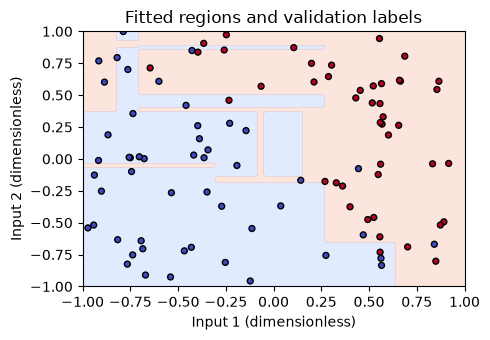

In [27]:
# Change only the minimum leaf sample count, with depth unrestricted.
# Larger leaves prevent rules based on very small groups but can also underfit.

# max_depth limits splits along a path; None removes this explicit depth bound.
# min_samples_leaf sets the minimum training sample count in every terminal leaf.
# ccp_alpha=0 disables cost-complexity pruning; positive values penalize extra leaves.
leaf_example = DecisionTreeClassifier(max_depth=None, min_samples_leaf=1, ccp_alpha=0.0, random_state=42)
# fit learns model parameters or tree rules from the supplied input rows and matching targets.
leaf_example.fit(X_toy_fit, y_toy_fit)
print('Actual depth / leaves:', leaf_example.get_depth(), leaf_example.get_n_leaves())
# predict applies the already fitted model; it does not update its learned rules.
leaf_example_fit_prediction = leaf_example.predict(X_toy_fit)
leaf_example_valid_prediction = leaf_example.predict(X_toy_valid)
# Give true labels first and predictions second. F1 is dimensionless, with larger values better.
leaf_example_fit_f1 = f1_score(y_toy_fit, leaf_example_fit_prediction)
leaf_example_valid_f1 = f1_score(y_toy_valid, leaf_example_valid_prediction)
print('leaf_example')
print('Training F1:', round(leaf_example_fit_f1, 3))
print('Validation F1:', round(leaf_example_valid_f1, 3))
plot_toy_regions(leaf_example)

**Try it yourself:** Compare leaf sizes 1, 5 and 15 with depth unrestricted. Does the best value have to be the largest?

Predict, run and compare. No formal written answer is needed.

Actual depth / leaves: 4 6
leaf_student
Training F1: 0.845
Validation F1: 0.865


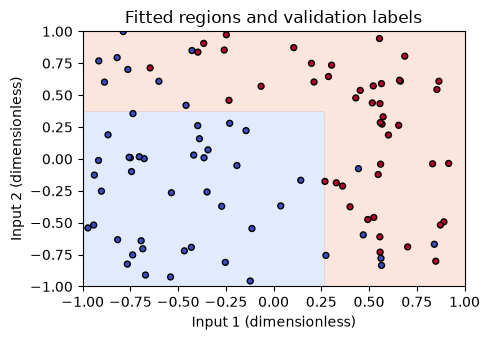

In [28]:
# Change only the minimum leaf sample count, with depth unrestricted.
# Larger leaves prevent rules based on very small groups but can also underfit.

# max_depth limits splits along a path; None removes this explicit depth bound.
# min_samples_leaf sets the minimum training sample count in every terminal leaf.
# ccp_alpha=0 disables cost-complexity pruning; positive values penalize extra leaves.
leaf_student = DecisionTreeClassifier(max_depth=None, min_samples_leaf=15, ccp_alpha=0.0, random_state=42)
# fit learns model parameters or tree rules from the supplied input rows and matching targets.
leaf_student.fit(X_toy_fit, y_toy_fit)
print('Actual depth / leaves:', leaf_student.get_depth(), leaf_student.get_n_leaves())
# predict applies the already fitted model; it does not update its learned rules.
leaf_student_fit_prediction = leaf_student.predict(X_toy_fit)
leaf_student_valid_prediction = leaf_student.predict(X_toy_valid)
# Give true labels first and predictions second. F1 is dimensionless, with larger values better.
leaf_student_fit_f1 = f1_score(y_toy_fit, leaf_student_fit_prediction)
leaf_student_valid_f1 = f1_score(y_toy_valid, leaf_student_valid_prediction)
print('leaf_student')
print('Training F1:', round(leaf_student_fit_f1, 3))
print('Validation F1:', round(leaf_student_valid_f1, 3))
plot_toy_regions(leaf_student)

In [29]:
# Change only the minimum leaf sample count, with depth unrestricted.
# Larger leaves prevent rules based on very small groups but can also underfit.
# PROVIDED SELF-CHECK: explicit blocks compare the requested settings; no loop needs to be reconstructed.

print('min_samples_leaf:', 1)
# max_depth limits splits along a path; None removes this explicit depth bound.
# min_samples_leaf sets the minimum training sample count in every terminal leaf.
# ccp_alpha=0 disables cost-complexity pruning; positive values penalize extra leaves.
comparison_tree = DecisionTreeClassifier(max_depth=None, min_samples_leaf=1, ccp_alpha=0.0, random_state=42)
# fit learns model parameters or tree rules from the supplied input rows and matching targets.
comparison_tree.fit(X_toy_fit, y_toy_fit)
print('Actual depth / leaves:', comparison_tree.get_depth(), comparison_tree.get_n_leaves())
# predict applies the already fitted model; it does not update its learned rules.
comparison_tree_fit_prediction = comparison_tree.predict(X_toy_fit)
comparison_tree_valid_prediction = comparison_tree.predict(X_toy_valid)
# Give true labels first and predictions second. F1 is dimensionless, with larger values better.
comparison_tree_fit_f1 = f1_score(y_toy_fit, comparison_tree_fit_prediction)
comparison_tree_valid_f1 = f1_score(y_toy_valid, comparison_tree_valid_prediction)
print('comparison_tree')
print('Training F1:', round(comparison_tree_fit_f1, 3))
print('Validation F1:', round(comparison_tree_valid_f1, 3))
print('min_samples_leaf:', 5)
comparison_tree = DecisionTreeClassifier(max_depth=None, min_samples_leaf=5, ccp_alpha=0.0, random_state=42)
comparison_tree.fit(X_toy_fit, y_toy_fit)
print('Actual depth / leaves:', comparison_tree.get_depth(), comparison_tree.get_n_leaves())
comparison_tree_fit_prediction = comparison_tree.predict(X_toy_fit)
comparison_tree_valid_prediction = comparison_tree.predict(X_toy_valid)
comparison_tree_fit_f1 = f1_score(y_toy_fit, comparison_tree_fit_prediction)
comparison_tree_valid_f1 = f1_score(y_toy_valid, comparison_tree_valid_prediction)
print('comparison_tree')
print('Training F1:', round(comparison_tree_fit_f1, 3))
print('Validation F1:', round(comparison_tree_valid_f1, 3))
print('min_samples_leaf:', 15)
comparison_tree = DecisionTreeClassifier(max_depth=None, min_samples_leaf=15, ccp_alpha=0.0, random_state=42)
comparison_tree.fit(X_toy_fit, y_toy_fit)
print('Actual depth / leaves:', comparison_tree.get_depth(), comparison_tree.get_n_leaves())
comparison_tree_fit_prediction = comparison_tree.predict(X_toy_fit)
comparison_tree_valid_prediction = comparison_tree.predict(X_toy_valid)
comparison_tree_fit_f1 = f1_score(y_toy_fit, comparison_tree_fit_prediction)
comparison_tree_valid_f1 = f1_score(y_toy_valid, comparison_tree_valid_prediction)
print('comparison_tree')
print('Training F1:', round(comparison_tree_fit_f1, 3))
print('Validation F1:', round(comparison_tree_valid_f1, 3))

min_samples_leaf: 1
Actual depth / leaves: 8 23
comparison_tree
Training F1: 1.0
Validation F1: 0.872
min_samples_leaf: 5
Actual depth / leaves: 5 13
comparison_tree
Training F1: 0.894
Validation F1: 0.884
min_samples_leaf: 15
Actual depth / leaves: 4 6
comparison_tree
Training F1: 0.845
Validation F1: 0.865


**Self-check:** Larger leaves make coarser regions. Too much restriction can underfit; best validation behavior is empirical, not monotonic.

<a id="b3"></a>

### B3: Cost-complexity pruning

ccp_alpha trades training impurity against leaf count; this is a pruning control, distinct from max_depth.

**Completed example:** Run unchanged first.

Actual depth / leaves: 8 23
prune_example
Training F1: 1.0
Validation F1: 0.872


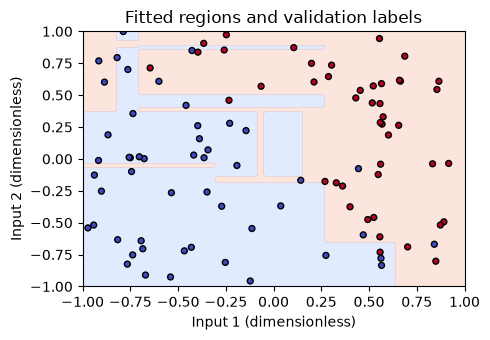

In [30]:
# ccp_alpha penalizes tree complexity during cost-complexity pruning.
# Compare the number of leaves as well as scores when the penalty changes.

# max_depth limits splits along a path; None removes this explicit depth bound.
# min_samples_leaf sets the minimum training sample count in every terminal leaf.
# ccp_alpha=0 disables cost-complexity pruning; positive values penalize extra leaves.
prune_example = DecisionTreeClassifier(max_depth=None, min_samples_leaf=1, ccp_alpha=0.0, random_state=42)
# fit learns model parameters or tree rules from the supplied input rows and matching targets.
prune_example.fit(X_toy_fit, y_toy_fit)
print('Actual depth / leaves:', prune_example.get_depth(), prune_example.get_n_leaves())
# predict applies the already fitted model; it does not update its learned rules.
prune_example_fit_prediction = prune_example.predict(X_toy_fit)
prune_example_valid_prediction = prune_example.predict(X_toy_valid)
# Give true labels first and predictions second. F1 is dimensionless, with larger values better.
prune_example_fit_f1 = f1_score(y_toy_fit, prune_example_fit_prediction)
prune_example_valid_f1 = f1_score(y_toy_valid, prune_example_valid_prediction)
print('prune_example')
print('Training F1:', round(prune_example_fit_f1, 3))
print('Validation F1:', round(prune_example_valid_f1, 3))
plot_toy_regions(prune_example)

**Try it yourself:** Compare alpha 0, 0.005 and 0.02. Record depth and leaves as well as scores.

Predict, run and compare. No formal written answer is needed.

Actual depth / leaves: 3 4
prune_student
Training F1: 0.879
Validation F1: 0.909


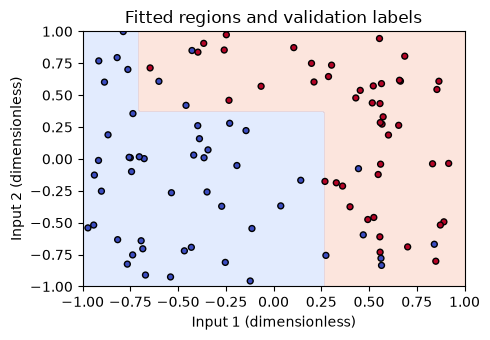

In [31]:
# ccp_alpha penalizes tree complexity during cost-complexity pruning.
# Compare the number of leaves as well as scores when the penalty changes.

# max_depth limits splits along a path; None removes this explicit depth bound.
# min_samples_leaf sets the minimum training sample count in every terminal leaf.
# ccp_alpha=0 disables cost-complexity pruning; positive values penalize extra leaves.
prune_student = DecisionTreeClassifier(max_depth=None, min_samples_leaf=1, ccp_alpha=0.02, random_state=42)
# fit learns model parameters or tree rules from the supplied input rows and matching targets.
prune_student.fit(X_toy_fit, y_toy_fit)
print('Actual depth / leaves:', prune_student.get_depth(), prune_student.get_n_leaves())
# predict applies the already fitted model; it does not update its learned rules.
prune_student_fit_prediction = prune_student.predict(X_toy_fit)
prune_student_valid_prediction = prune_student.predict(X_toy_valid)
# Give true labels first and predictions second. F1 is dimensionless, with larger values better.
prune_student_fit_f1 = f1_score(y_toy_fit, prune_student_fit_prediction)
prune_student_valid_f1 = f1_score(y_toy_valid, prune_student_valid_prediction)
print('prune_student')
print('Training F1:', round(prune_student_fit_f1, 3))
print('Validation F1:', round(prune_student_valid_f1, 3))
plot_toy_regions(prune_student)

In [32]:
# ccp_alpha penalizes tree complexity during cost-complexity pruning.
# Compare the number of leaves as well as scores when the penalty changes.
# PROVIDED SELF-CHECK: explicit blocks compare the requested settings; no loop needs to be reconstructed.

print('ccp_alpha:', 0)
# max_depth limits splits along a path; None removes this explicit depth bound.
# min_samples_leaf sets the minimum training sample count in every terminal leaf.
# ccp_alpha=0 disables cost-complexity pruning; positive values penalize extra leaves.
comparison_tree = DecisionTreeClassifier(max_depth=None, min_samples_leaf=1, ccp_alpha=0, random_state=42)
# fit learns model parameters or tree rules from the supplied input rows and matching targets.
comparison_tree.fit(X_toy_fit, y_toy_fit)
print('Actual depth / leaves:', comparison_tree.get_depth(), comparison_tree.get_n_leaves())
# predict applies the already fitted model; it does not update its learned rules.
comparison_tree_fit_prediction = comparison_tree.predict(X_toy_fit)
comparison_tree_valid_prediction = comparison_tree.predict(X_toy_valid)
# Give true labels first and predictions second. F1 is dimensionless, with larger values better.
comparison_tree_fit_f1 = f1_score(y_toy_fit, comparison_tree_fit_prediction)
comparison_tree_valid_f1 = f1_score(y_toy_valid, comparison_tree_valid_prediction)
print('comparison_tree')
print('Training F1:', round(comparison_tree_fit_f1, 3))
print('Validation F1:', round(comparison_tree_valid_f1, 3))
print('ccp_alpha:', 0.005)
comparison_tree = DecisionTreeClassifier(max_depth=None, min_samples_leaf=1, ccp_alpha=0.005, random_state=42)
comparison_tree.fit(X_toy_fit, y_toy_fit)
print('Actual depth / leaves:', comparison_tree.get_depth(), comparison_tree.get_n_leaves())
comparison_tree_fit_prediction = comparison_tree.predict(X_toy_fit)
comparison_tree_valid_prediction = comparison_tree.predict(X_toy_valid)
comparison_tree_fit_f1 = f1_score(y_toy_fit, comparison_tree_fit_prediction)
comparison_tree_valid_f1 = f1_score(y_toy_valid, comparison_tree_valid_prediction)
print('comparison_tree')
print('Training F1:', round(comparison_tree_fit_f1, 3))
print('Validation F1:', round(comparison_tree_valid_f1, 3))
print('ccp_alpha:', 0.02)
comparison_tree = DecisionTreeClassifier(max_depth=None, min_samples_leaf=1, ccp_alpha=0.02, random_state=42)
comparison_tree.fit(X_toy_fit, y_toy_fit)
print('Actual depth / leaves:', comparison_tree.get_depth(), comparison_tree.get_n_leaves())
comparison_tree_fit_prediction = comparison_tree.predict(X_toy_fit)
comparison_tree_valid_prediction = comparison_tree.predict(X_toy_valid)
comparison_tree_fit_f1 = f1_score(y_toy_fit, comparison_tree_fit_prediction)
comparison_tree_valid_f1 = f1_score(y_toy_valid, comparison_tree_valid_prediction)
print('comparison_tree')
print('Training F1:', round(comparison_tree_fit_f1, 3))
print('Validation F1:', round(comparison_tree_valid_f1, 3))

ccp_alpha: 0
Actual depth / leaves: 8 23
comparison_tree
Training F1: 1.0
Validation F1: 0.872
ccp_alpha: 0.005
Actual depth / leaves: 8 23
comparison_tree
Training F1: 1.0
Validation F1: 0.872
ccp_alpha: 0.02
Actual depth / leaves: 3 4
comparison_tree
Training F1: 0.879
Validation F1: 0.909


**Self-check:** Increasing the penalty generally removes leaves. A smaller tree is not automatically more accurate on validation.

<a id="b4"></a>

### B4: Sensitivity to training samples

Instability concerns changes to the fitted rules when the sample changes, not just changing a model seed.

**Completed example:** Run unchanged first.

In [33]:
# Slicing away early rows changes the training sample; the validation rows stay fixed.
# Count disagreements between model predictions, not disagreements with true labels.
# A matching root does not imply that all lower branches are identical.

# max_depth limits splits along a path; None removes this explicit depth bound.
stable_example = DecisionTreeClassifier(max_depth=3, random_state=42)
# fit learns model parameters or tree rules from the supplied input rows and matching targets.
stable_example.fit(X_toy_fit, y_toy_fit)
print('Reference root feature / threshold:', stable_example.tree_.feature[0], stable_example.tree_.threshold[0])

Reference root feature / threshold: 0 0.2686934322118759


**Try it yourself:** Compare removing 12 and 24 rows. Can the root remain unchanged while other predictions change?

Predict, run and compare. No formal written answer is needed.

In [34]:
# Slicing away early rows changes the training sample; the validation rows stay fixed.
# Count disagreements between model predictions, not disagreements with true labels.
# A matching root does not imply that all lower branches are identical.

remove_rows = 12
# max_depth limits splits along a path; None removes this explicit depth bound.
changed_tree = DecisionTreeClassifier(max_depth=3, random_state=42)
# fit learns model parameters or tree rules from the supplied input rows and matching targets.
changed_tree.fit(X_toy_fit[remove_rows:], y_toy_fit[remove_rows:])
print('New root:', changed_tree.tree_.feature[0], changed_tree.tree_.threshold[0])
# predict applies the already fitted model; it does not update its learned rules.
stable_example_valid_prediction = stable_example.predict(X_toy_valid)
changed_tree_valid_prediction = changed_tree.predict(X_toy_valid)
print('Validation disagreements:', np.sum(stable_example_valid_prediction != changed_tree_valid_prediction))

New root: 0 0.3767579346895218
Validation disagreements: 3


In [35]:
# Slicing away early rows changes the training sample; the validation rows stay fixed.
# Count disagreements between model predictions, not disagreements with true labels.
# A matching root does not imply that all lower branches are identical.
# PROVIDED SELF-CHECK: explicit blocks compare the requested settings; no loop needs to be reconstructed.

# max_depth limits splits along a path; None removes this explicit depth bound.
model = DecisionTreeClassifier(max_depth=3, random_state=42)
# fit learns model parameters or tree rules from the supplied input rows and matching targets.
model.fit(X_toy_fit[12:], y_toy_fit[12:])
# predict applies the already fitted model; it does not update its learned rules.
model_valid_prediction = model.predict(X_toy_valid)
stable_example_valid_prediction = stable_example.predict(X_toy_valid)
print('Rows removed / disagreements:', 12, np.sum(model_valid_prediction != stable_example_valid_prediction))
model = DecisionTreeClassifier(max_depth=3, random_state=42)
model.fit(X_toy_fit[24:], y_toy_fit[24:])
model_valid_prediction = model.predict(X_toy_valid)
stable_example_valid_prediction = stable_example.predict(X_toy_valid)
print('Rows removed / disagreements:', 24, np.sum(model_valid_prediction != stable_example_valid_prediction))

Rows removed / disagreements: 12 3
Rows removed / disagreements: 24 0


**Self-check:** Yes: lower nodes can change even when the root matches. Sample removal also changes training size and composition, so this is a demonstration, not an isolated variance estimate.

<a id="c1"></a>

### C1: Bootstrap duplication

A bootstrap sample draws with replacement. Its number of draws can equal the source size while its number of distinct rows is smaller.

**Completed example:** Run unchanged first.

In [36]:
# The integers represent original row positions, not new physical observations.
# Sampling with replacement permits repeated positions within one bootstrap sample.
# The distinct-row count can be smaller than the number of draws.

# Reset the seed so differences reflect the draw count rather than a different random sequence.
bootstrap_rng = np.random.default_rng(42)
bootstrap_ids = bootstrap_rng.choice(12, size=12, replace=True)
print('Draws:', bootstrap_ids)
print('Distinct original rows:', len(np.unique(bootstrap_ids)))

Draws: [ 1  9  7  5  5 10  1  8  2  1  6 11]
Distinct original rows: 9


**Try it yourself:** Use 24 draws. Explain why this does not create 24 independent original observations.

Predict, run and compare. No formal written answer is needed.

In [37]:
# The integers represent original row positions, not new physical observations.
# Sampling with replacement permits repeated positions within one bootstrap sample.
# The distinct-row count can be smaller than the number of draws.

# Reset the seed so differences reflect the draw count rather than a different random sequence.
bootstrap_rng = np.random.default_rng(42)
student_draws = bootstrap_rng.choice(12, size=24, replace=True)
print('Draw count / distinct rows:', len(student_draws), len(np.unique(student_draws)))

Draw count / distinct rows: 24 10


**Self-check:** Repeated indices duplicate existing rows. Sampling does not create new physical cutter observations.

<a id="c2"></a>

### C2: Bagging trees

Bagging averages class probabilities from trees fitted to bootstrap samples.

**Completed example:** Run unchanged first.

In [38]:
# Bagging fits member trees to bootstrap samples and averages their class probabilities.
# The estimator argument specifies the kind of model used for each member.

# max_depth limits splits along a path; None removes this explicit depth bound.
ensemble = BaggingClassifier(estimator=DecisionTreeClassifier(random_state=42), n_estimators=5, random_state=42)
# fit learns model parameters or tree rules from the supplied input rows and matching targets.
ensemble.fit(X_toy_fit, y_toy_fit)
# predict applies the already fitted model; it does not update its learned rules.
ensemble_fit_prediction = ensemble.predict(X_toy_fit)
ensemble_valid_prediction = ensemble.predict(X_toy_valid)
# Give true labels first and predictions second. F1 is dimensionless, with larger values better.
ensemble_fit_f1 = f1_score(y_toy_fit, ensemble_fit_prediction)
ensemble_valid_f1 = f1_score(y_toy_valid, ensemble_valid_prediction)
print('Ensemble')
print('Training F1:', round(ensemble_fit_f1, 3))
print('Validation F1:', round(ensemble_valid_f1, 3))

Ensemble
Training F1: 0.955
Validation F1: 0.882


**Try it yourself:** Compare 5 and 50 bagged trees. Why does averaging not guarantee removal of systematic bias?

Predict, run and compare. No formal written answer is needed.

In [39]:
# Bagging fits member trees to bootstrap samples and averages their class probabilities.
# The estimator argument specifies the kind of model used for each member.

# max_depth limits splits along a path; None removes this explicit depth bound.
ensemble = BaggingClassifier(estimator=DecisionTreeClassifier(random_state=42), n_estimators=50, random_state=42)
# fit learns model parameters or tree rules from the supplied input rows and matching targets.
ensemble.fit(X_toy_fit, y_toy_fit)
# predict applies the already fitted model; it does not update its learned rules.
ensemble_fit_prediction = ensemble.predict(X_toy_fit)
ensemble_valid_prediction = ensemble.predict(X_toy_valid)
# Give true labels first and predictions second. F1 is dimensionless, with larger values better.
ensemble_fit_f1 = f1_score(y_toy_fit, ensemble_fit_prediction)
ensemble_valid_f1 = f1_score(y_toy_valid, ensemble_valid_prediction)
print('Ensemble')
print('Training F1:', round(ensemble_fit_f1, 3))
print('Validation F1:', round(ensemble_valid_f1, 3))

Ensemble
Training F1: 0.992
Validation F1: 0.905


**Self-check:** Averaging can reduce instability, but trees can share systematic errors or training-population limitations.

<a id="c4"></a>

### C4: More trees versus deeper trees

n_estimators controls ensemble size; max_depth controls each tree capacity. They are different controls.

**Completed example:** Run unchanged first.

In [40]:
# n_estimators is the number of trees; max_depth limits the capacity of each tree.
# First change tree count with depth fixed, then change depth with tree count fixed.

# The forest combines bootstrapped trees and random feature candidates at each split.
# n_estimators counts member trees; random_state makes the randomized fit reproducible.
# n_jobs=1 uses one worker for reproducible, modest resource use in this exercise.
ensemble = RandomForestClassifier(n_estimators=10, max_depth=3, random_state=42, n_jobs=1)
# fit learns model parameters or tree rules from the supplied input rows and matching targets.
ensemble.fit(X_toy_fit, y_toy_fit)
# predict applies the already fitted model; it does not update its learned rules.
ensemble_fit_prediction = ensemble.predict(X_toy_fit)
ensemble_valid_prediction = ensemble.predict(X_toy_valid)
# Give true labels first and predictions second. F1 is dimensionless, with larger values better.
ensemble_fit_f1 = f1_score(y_toy_fit, ensemble_fit_prediction)
ensemble_valid_f1 = f1_score(y_toy_valid, ensemble_valid_prediction)
print('Ensemble')
print('Training F1:', round(ensemble_fit_f1, 3))
print('Validation F1:', round(ensemble_valid_f1, 3))

Ensemble
Training F1: 0.891
Validation F1: 0.925


**Try it yourself:** Compare 10, 50 and 150 trees while holding depth=3. Then compare depth=8 at 150 trees. Separate the two effects.

Predict, run and compare. No formal written answer is needed.

In [41]:
# n_estimators is the number of trees; max_depth limits the capacity of each tree.
# First change tree count with depth fixed, then change depth with tree count fixed.

# The forest combines bootstrapped trees and random feature candidates at each split.
# n_estimators counts member trees; random_state makes the randomized fit reproducible.
# n_jobs=1 uses one worker for reproducible, modest resource use in this exercise.
ensemble = RandomForestClassifier(n_estimators=150, max_depth=3, random_state=42, n_jobs=1)
# fit learns model parameters or tree rules from the supplied input rows and matching targets.
ensemble.fit(X_toy_fit, y_toy_fit)
# predict applies the already fitted model; it does not update its learned rules.
ensemble_fit_prediction = ensemble.predict(X_toy_fit)
ensemble_valid_prediction = ensemble.predict(X_toy_valid)
# Give true labels first and predictions second. F1 is dimensionless, with larger values better.
ensemble_fit_f1 = f1_score(y_toy_fit, ensemble_fit_prediction)
ensemble_valid_f1 = f1_score(y_toy_valid, ensemble_valid_prediction)
print('Ensemble')
print('Training F1:', round(ensemble_fit_f1, 3))
print('Validation F1:', round(ensemble_valid_f1, 3))

Ensemble
Training F1: 0.899
Validation F1: 0.928


In [42]:
# n_estimators is the number of trees; max_depth limits the capacity of each tree.
# First change tree count with depth fixed, then change depth with tree count fixed.
# PROVIDED SELF-CHECK: explicit blocks compare the requested settings; no loop needs to be reconstructed.

# The forest combines bootstrapped trees and random feature candidates at each split.
# n_estimators counts member trees; random_state makes the randomized fit reproducible.
# n_jobs=1 uses one worker for reproducible, modest resource use in this exercise.
model = RandomForestClassifier(n_estimators=10, max_depth=3, random_state=42, n_jobs=1)
# fit learns model parameters or tree rules from the supplied input rows and matching targets.
model.fit(X_toy_fit, y_toy_fit)
# predict applies the already fitted model; it does not update its learned rules.
model_fit_prediction = model.predict(X_toy_fit)
# Give true labels first and predictions second. F1 is dimensionless, with larger values better.
comparison_training_f1 = f1_score(y_toy_fit, model_fit_prediction)
model_valid_prediction = model.predict(X_toy_valid)
comparison_validation_f1 = f1_score(y_toy_valid, model_valid_prediction)
print('Trees / depth / training F1 / validation F1:', 10, 3, round(comparison_training_f1, 3), round(comparison_validation_f1, 3))
model = RandomForestClassifier(n_estimators=50, max_depth=3, random_state=42, n_jobs=1)
model.fit(X_toy_fit, y_toy_fit)
model_fit_prediction = model.predict(X_toy_fit)
comparison_training_f1 = f1_score(y_toy_fit, model_fit_prediction)
model_valid_prediction = model.predict(X_toy_valid)
comparison_validation_f1 = f1_score(y_toy_valid, model_valid_prediction)
print('Trees / depth / training F1 / validation F1:', 50, 3, round(comparison_training_f1, 3), round(comparison_validation_f1, 3))
model = RandomForestClassifier(n_estimators=150, max_depth=3, random_state=42, n_jobs=1)
model.fit(X_toy_fit, y_toy_fit)
model_fit_prediction = model.predict(X_toy_fit)
comparison_training_f1 = f1_score(y_toy_fit, model_fit_prediction)
model_valid_prediction = model.predict(X_toy_valid)
comparison_validation_f1 = f1_score(y_toy_valid, model_valid_prediction)
print('Trees / depth / training F1 / validation F1:', 150, 3, round(comparison_training_f1, 3), round(comparison_validation_f1, 3))
model = RandomForestClassifier(n_estimators=150, max_depth=8, random_state=42, n_jobs=1)
model.fit(X_toy_fit, y_toy_fit)
model_fit_prediction = model.predict(X_toy_fit)
comparison_training_f1 = f1_score(y_toy_fit, model_fit_prediction)
model_valid_prediction = model.predict(X_toy_valid)
comparison_validation_f1 = f1_score(y_toy_valid, model_valid_prediction)
print('Trees / depth / training F1 / validation F1:', 150, 8, round(comparison_training_f1, 3), round(comparison_validation_f1, 3))

Trees / depth / training F1 / validation F1: 10 3 0.891 0.925


Trees / depth / training F1 / validation F1: 50 3 0.898 0.928


Trees / depth / training F1 / validation F1: 150 3 0.899 0.928


Trees / depth / training F1 / validation F1: 150 8 1.0 0.938


**Self-check:** More trees stabilize an average; deeper trees change member capacity. Neither control guarantees transfer to another physical group.

<a id="e1"></a>

### E1: Optional boosting overview

Boosting fits stages sequentially to improve an additive model. It is not independent bootstrap averaging.

**Completed example:** Run unchanged first.

In [43]:
# Boosting builds an additive model in sequential stages rather than independent bootstrap averaging.
# learning_rate scales the contribution of each stage; n_estimators controls the stage count.
# Compare these controls one at a time before discussing their combined effect.

boost = GradientBoostingClassifier(n_estimators=30, learning_rate=0.1, max_depth=2, random_state=42)
# fit learns model parameters or tree rules from the supplied input rows and matching targets.
boost.fit(X_fit, y_fit)
# predict applies the already fitted model; it does not update its learned rules.
boost_fit_prediction = boost.predict(X_fit)
boost_valid_prediction = boost.predict(X_valid)
# Give true labels first and predictions second. F1 is dimensionless, with larger values better.
# macro averages class-wise F1 equally; labels fixes class order and zero_division handles undefined ratios.
boost_fit_f1 = f1_score(y_fit, boost_fit_prediction, labels=[0, 1, 2], average='macro', zero_division=0)
boost_valid_f1 = f1_score(y_valid, boost_valid_prediction, labels=[0, 1, 2], average='macro', zero_division=0)
print('30 stages')
print('Training macro-F1:', round(boost_fit_f1, 3))
print('Validation macro-F1:', round(boost_valid_f1, 3))

30 stages
Training macro-F1: 1.0
Validation macro-F1: 0.56


**Try it yourself:** Compare stage count and learning rate one at a time. Explain why smaller steps may need more stages.

Predict, run and compare. No formal written answer is needed.

In [44]:
# Boosting builds an additive model in sequential stages rather than independent bootstrap averaging.
# learning_rate scales the contribution of each stage; n_estimators controls the stage count.
# Compare these controls one at a time before discussing their combined effect.

boost_student = GradientBoostingClassifier(n_estimators=100, learning_rate=0.03, max_depth=2, random_state=42)
# fit learns model parameters or tree rules from the supplied input rows and matching targets.
boost_student.fit(X_fit, y_fit)
# predict applies the already fitted model; it does not update its learned rules.
boost_student_fit_prediction = boost_student.predict(X_fit)
boost_student_valid_prediction = boost_student.predict(X_valid)
# Give true labels first and predictions second. F1 is dimensionless, with larger values better.
# macro averages class-wise F1 equally; labels fixes class order and zero_division handles undefined ratios.
boost_student_fit_f1 = f1_score(y_fit, boost_student_fit_prediction, labels=[0, 1, 2], average='macro', zero_division=0)
boost_student_valid_f1 = f1_score(y_valid, boost_student_valid_prediction, labels=[0, 1, 2], average='macro', zero_division=0)
print('100 stages, 0.03')
print('Training macro-F1:', round(boost_student_fit_f1, 3))
print('Validation macro-F1:', round(boost_student_valid_f1, 3))

100 stages, 0.03
Training macro-F1: 1.0
Validation macro-F1: 0.56


In [45]:
# Boosting builds an additive model in sequential stages rather than independent bootstrap averaging.
# learning_rate scales the contribution of each stage; n_estimators controls the stage count.
# Compare these controls one at a time before discussing their combined effect.
# PROVIDED SELF-CHECK: explicit blocks compare the requested settings; no loop needs to be reconstructed.

rows = []
model = GradientBoostingClassifier(n_estimators=30, learning_rate=0.1, max_depth=2, random_state=42)
# fit learns model parameters or tree rules from the supplied input rows and matching targets.
model.fit(X_fit, y_fit)
# predict applies the already fitted model; it does not update its learned rules.
model_fit_prediction = model.predict(X_fit)
model_valid_prediction = model.predict(X_valid)
# Give true labels first and predictions second. F1 is dimensionless, with larger values better.
# macro averages class-wise F1 equally; labels fixes class order and zero_division handles undefined ratios.
model_fit_f1 = f1_score(y_fit, model_fit_prediction, labels=[0, 1, 2], average='macro', zero_division=0)
model_valid_f1 = f1_score(y_valid, model_valid_prediction, labels=[0, 1, 2], average='macro', zero_division=0)
comparison_score_row = [str(30) + ' stages; rate ' + str(0.1), model_fit_f1, model_valid_f1]
rows.append(comparison_score_row)
model = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=2, random_state=42)
model.fit(X_fit, y_fit)
model_fit_prediction = model.predict(X_fit)
model_valid_prediction = model.predict(X_valid)
model_fit_f1 = f1_score(y_fit, model_fit_prediction, labels=[0, 1, 2], average='macro', zero_division=0)
model_valid_f1 = f1_score(y_valid, model_valid_prediction, labels=[0, 1, 2], average='macro', zero_division=0)
comparison_score_row = [str(100) + ' stages; rate ' + str(0.1), model_fit_f1, model_valid_f1]
rows.append(comparison_score_row)
model = GradientBoostingClassifier(n_estimators=100, learning_rate=0.03, max_depth=2, random_state=42)
model.fit(X_fit, y_fit)
model_fit_prediction = model.predict(X_fit)
model_valid_prediction = model.predict(X_valid)
model_fit_f1 = f1_score(y_fit, model_fit_prediction, labels=[0, 1, 2], average='macro', zero_division=0)
model_valid_f1 = f1_score(y_valid, model_valid_prediction, labels=[0, 1, 2], average='macro', zero_division=0)
comparison_score_row = [str(100) + ' stages; rate ' + str(0.03), model_fit_f1, model_valid_f1]
rows.append(comparison_score_row)
comparison_table = pd.DataFrame(rows, columns=['Model', 'Training macro-F1', 'Validation macro-F1'])
# Round only the display; retain full-precision values when comparing candidates or checking ties.
display(comparison_table.round(3))

,Model,Training macro-F1,Validation macro-F1
0,30 stages; rate 0.1,1.0,0.56
1,100 stages; rate 0.1,1.0,0.56
2,100 stages; rate 0.03,1.0,0.56


**Self-check:** Learning rate scales each stage contribution; stage count controls how many updates are added. Validation behavior depends on their combination.

<a id="e2"></a>

### E2: Optional correlated duplicate input

An exact duplicate carries no new measurement information but changes which columns a forest can split on.

**Completed example:** Run unchanged first.

In [46]:
# An exact copy of force_y_sd adds a column but no new physical measurement information.
# Make the same added column in training and validation to preserve matching input structure.
# Shuffling one duplicate leaves the other available as a substitute.

duplicate_fit = X_fit.copy()
duplicate_valid = X_valid.copy()
duplicate_fit['force_y_sd_copy'] = duplicate_fit['force_y_sd']
duplicate_valid['force_y_sd_copy'] = duplicate_valid['force_y_sd']
# min_samples_leaf sets the minimum training sample count in every terminal leaf.
# The forest combines bootstrapped trees and random feature candidates at each split.
# n_estimators counts member trees; random_state makes the randomized fit reproducible.
# n_jobs=1 uses one worker for reproducible, modest resource use in this exercise.
duplicate_model = RandomForestClassifier(n_estimators=100, max_depth=8, min_samples_leaf=5, random_state=42, n_jobs=1)
# fit learns model parameters or tree rules from the supplied input rows and matching targets.
duplicate_model.fit(duplicate_fit, y_fit)
feature_importance = pd.Series(duplicate_model.feature_importances_, index=duplicate_fit.columns)
sorted_importance = feature_importance.sort_values(ascending=False)
top_importance = sorted_importance.head(6)
print(top_importance)

force_y_mean      0.158439
force_z_sd        0.143900
ae_rms_mean       0.139162
force_x_sd        0.138585
vibration_x_sd    0.120568
vibration_z_sd    0.102397
dtype: float64


**Try it yourself:** Inspect both duplicate columns. Explain how a substitute input can mask single-column dependence; do not assume the two values must match.

Predict, run and compare. No formal written answer is needed.

In [47]:
# An exact copy of force_y_sd adds a column but no new physical measurement information.
# Make the same added column in training and validation to preserve matching input structure.
# Shuffling one duplicate leaves the other available as a substitute.

# Refitting is not performed: repeatedly shuffle one validation column and measure the score drop.
# Five shuffles give a mean and repeat SD for each column; the score is macro-F1 here.
duplicate_perm = permutation_importance(duplicate_model, duplicate_valid, y_valid, scoring='f1_macro', n_repeats=5, random_state=42)
feature_importance = pd.Series(duplicate_perm.importances_mean, index=duplicate_fit.columns)
sorted_importance = feature_importance.sort_values(ascending=False)
# Round only the display; retain full-precision values when comparing candidates or checking ties.
rounded_importance = sorted_importance.round(3)
print(rounded_importance)

vibration_x_sd     0.119
vibration_z_sd     0.054
force_x_sd         0.051
force_z_sd         0.026
ae_rms_mean        0.022
force_z_mean       0.005
force_x_mean       0.000
force_y_sd         0.000
force_y_sd_copy    0.000
ae_rms_sd          0.000
force_y_mean      -0.002
vibration_y_sd    -0.004
dtype: float64


**Self-check:** The forest may use the columns unequally. Shuffling one leaves the other intact, so individual drops need not reflect dependence on the shared information.

## References

- [scikit-learn: Decision trees](https://scikit-learn.org/stable/modules/tree.html)
- [scikit-learn: Ensembles](https://scikit-learn.org/stable/modules/ensemble.html)
- [scikit-learn: Permutation importance](https://scikit-learn.org/stable/modules/permutation_importance.html)
- [PHM Society: 2010 Data Challenge](https://phmsociety.org/phm_competition/2010-phm-society-conference-data-challenge/)
- [Course PHM feature documentation](https://github.com/WSU-AI-in-ME/ai-in-me-1/blob/main/data/phm2010/features/README.md)